# Cavity field test: Python vs MATLAB

Compare the saved outputs of the two independent **Gaussian-map** calculations, using the same organization as `1.meshgrid_test/compare_results.ipynb`.

1. Run `cavity_field_test.ipynb` to export `inputs.mat` and `python_results.mat`.
2. Run `cavity_field_test.mlx` in MATLAB to export `matlab_results.mat`.
3. Use **Restart Kernel and Run All** in this notebook.

This notebook reads the results only: it does not calculate fields, start MATLAB, or overwrite files. Both producers generate Gaussian maps directly in memory; no field-text import is tested.

Rerun both implementations after changing inputs. The result files have no input fingerprint, so their presence or timestamps alone cannot establish that they represent the same case.


In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import Markdown, display

# Find the project from the workspace, project, test, or notebook folder.
current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "2.cavity_field_test"

# Use the same dashed gray grid as the Python meshgrid notebook.
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})


## 1. Load the two result files

The paths and modification times help identify the files being compared; timestamps alone do not prove that their inputs match. Scalars, vectors, and matrices are initially loaded with their stored dimensions.


In [2]:
python_file = test_directory / "python_results.mat"
matlab_file = test_directory / "matlab_results.mat"

for result_file in (python_file, matlab_file):
    if not result_file.is_file():
        raise FileNotFoundError(
            f"Missing {result_file}. Run both cavity-field tests before comparing."
        )
    modified = datetime.fromtimestamp(result_file.stat().st_mtime)
    print(f"{result_file.name}: {result_file}")
    print(f"  Last modified (local time): {modified:%Y-%m-%d %H:%M:%S}")

python_results = loadmat(python_file)
matlab_results = loadmat(matlab_file)


python_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\2.cavity_field_test\python_results.mat
  Last modified (local time): 2026-10-15 10:03:30
matlab_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\2.cavity_field_test\matlab_results.mat
  Last modified (local time): 2026-10-15 14:11:05


## 2. Comparison rules

Compare all **19 numerical outputs** plus the exact cavity-name/column order.

- Scalars contain one value. Row/column orientation is ignored only for declared vectors.
- Local `z_mm, e_z` are matrices with one column per cavity. Global `ez, C3, vpz, alfaz` must have one row per solver node and one column per cavity.
- No matrix is flattened, no fields are rescaled, and no interpolation is performed by this notebook.
- The test uses the same tolerance as test 1: `abs(Python - MATLAB) <= atol + rtol * abs(MATLAB)`, at every entry.
- Missing variables, unexpected dimensions, nonnumeric values, NaN or infinity cannot pass.
- Additional exported variables are NOT TESTED until comparison rules are added.

`z_mm, e_z` check the Gaussian generator; `zi, z, dz, dt, I0, U0, s, betae, k0` check the supporting grid/reference quantities; `ez, C3` check placement/interpolation/normalization. `vpz, alfaz` are zero placeholders for this standing-wave case. The four integral diagnostics check recovered `RtoQ` and `M` on both samplings.

Unlike the meshgrid test's `Nesz`, these outputs require **no indexing conversion**.


In [3]:
rtol = 1e-10
atol = 1e-12

# Name: (expected structure, units)
variables = {
    "z_mm":       ("matrix", "mm"),
    "e_z":        ("matrix", "mm^(-3/2)"),
    "I0":         ("scalar", "A"),
    "U0":         ("scalar", "kV"),
    "s":          ("scalar", "1"),
    "betae":      ("scalar", "1/mm"),
    "k0":         ("vector", "1/mm"),
    "dz":         ("scalar", "mm"),
    "zi":         ("vector", "mm"),
    "z":          ("vector", "1"),
    "dt":         ("scalar", "1"),
    "ez":         ("matrix", "mm^(-3/2)"),
    "C3":         ("matrix", "1"),
    "vpz":        ("matrix", "unused (zero)"),
    "alfaz":      ("matrix", "unused (zero)"),
    "RtoQ_local": ("vector", "ohm"),
    "M_local":    ("vector", "1"),
    "RtoQ_grid":  ("vector", "ohm"),
    "M_grid":     ("vector", "1"),
}


In [4]:
# Check the names before interpreting any matrix columns.
python_names = python_results.get("cavityname", np.array([]))
matlab_names = matlab_results.get("cavityname", np.array([]))
python_names = tuple(python_names.item().split()) if python_names.size == 1 and python_names.dtype.kind in "US" else ()
matlab_names = tuple(matlab_names.item().split()) if matlab_names.size == 1 and matlab_names.dtype.kind in "US" else ()
names_match = bool(python_names) and python_names == matlab_names
names_match = names_match and len(set(python_names)) == len(python_names)
Nc = len(python_names)

comparison = []
pairs = {}  # Validated copies used by the plots; saved arrays stay unchanged.

for name, (structure, units) in variables.items():
    python_values = python_results.get(name)
    matlab_values = matlab_results.get(name)
    row = {
        "name": name,
        "units": units,
        "python_shape": None if python_values is None else python_values.shape,
        "matlab_shape": None if matlab_values is None else matlab_values.shape,
        "max_absolute": None,
        "max_relative": None,
        "status": "NOT TESTED",
        "note": "",
    }
    comparison.append(row)

    if python_values is None or matlab_values is None:
        row["note"] = "Missing variable in one or both result files."
        continue

    # These Gaussian-field outputs are real numbers, not text, objects, or complex fields.
    if any(values.dtype.kind not in "iuf" for values in (python_values, matlab_values)):
        row["note"] = "Expected real numeric values."
        continue

    shape_ok = True
    for values, results in ((python_values, python_results),
                            (matlab_values, matlab_results)):
        if structure == "scalar":
            shape_ok = shape_ok and values.shape == (1, 1)
        elif structure == "vector":
            shape_ok = shape_ok and values.ndim == 2 and 1 in values.shape and values.size > 0
            expected_size = results.get("zi", np.array([])).size if name in ("zi", "z") else Nc
            shape_ok = shape_ok and expected_size > 0 and values.size == expected_size
        else:
            if name in ("z_mm", "e_z"):
                local_z = results.get("z_mm", np.empty((0, 0)))
                shape_ok = shape_ok and local_z.ndim == 2 and local_z.shape[0] >= 2
                expected_shape = (local_z.shape[0], Nc)
            else:
                zi_values = results.get("zi", np.array([]))
                shape_ok = shape_ok and zi_values.size >= 2
                expected_shape = (zi_values.size, Nc)
            shape_ok = shape_ok and Nc > 0 and values.shape == expected_shape

    if not shape_ok:
        row["note"] = f"Unexpected {structure} dimensions."
        continue

    # Float copies also avoid unsigned-integer subtraction in the error calculation.
    python_values = python_values.astype(float)
    matlab_values = matlab_values.astype(float)
    if structure != "matrix":
        python_values = python_values.reshape(-1)
        matlab_values = matlab_values.reshape(-1)

    if python_values.shape != matlab_values.shape:
        row["note"] = "Dimensions differ after allowed vector-orientation adjustment."
        continue

    if not (np.all(np.isfinite(python_values)) and np.all(np.isfinite(matlab_values))):
        row["note"] = "NaN or infinity found."
        continue

    pairs[name] = (python_values, matlab_values)
    absolute_error = np.abs(python_values - matlab_values)
    row["max_absolute"] = np.max(absolute_error)

    # Relative error is defined only where the MATLAB reference is nonzero.
    nonzero = matlab_values != 0
    if np.any(nonzero):
        row["max_relative"] = np.max(
            absolute_error[nonzero] / np.abs(matlab_values[nonzero])
        )

    tolerance = atol + rtol * np.abs(matlab_values)
    passed = np.all(absolute_error <= tolerance)
    row["note"] = "Absolute + relative tolerance"

    row["status"] = "PASS" if passed else "FAIL"

# Do not silently ignore a new output added to either implementation.
exported_names = {
    name for results in (python_results, matlab_results)
    for name in results if not name.startswith("__")
}
extra_names = sorted(exported_names - variables.keys() - {'cavityname'})
all_passed = names_match and all(row["status"] == "PASS" for row in comparison) and not extra_names


## 3. Numerical summary

**Max absolute error** uses the units listed in the table. **Max relative error** is dimensionless and is calculated only over nonzero MATLAB entries (a dash means there are none). Entries whose MATLAB value is zero are still checked using `atol`. A small maximum absolute error is not sufficient on its own: the tolerance is checked separately at each entry.


In [5]:
def format_error(value):
    return "-" if value is None else f"{value:.3e}"


table = [
    "| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |",
    "|---|---|---|---|---|---|---|---|",
]
for row in comparison:
    table.append(
        f"| {row['name']} | {row['units']} | {row['python_shape']} | {row['matlab_shape']} "
        f"| {format_error(row['max_absolute'])} | {format_error(row['max_relative'])} "
        f"| {row['status']} | {row['note']} |"
    )
display(Markdown("\n".join(table)))

if extra_names:
    print("NOT TESTED: unexpected exported variables:", ", ".join(extra_names))

passed_count = sum(row["status"] == "PASS" for row in comparison)
print(f"Tolerance for floating-point quantities: rtol={rtol:g}, atol={atol:g}")
print(f"{passed_count}/{len(variables)} expected quantities passed.")
print("Overall: PASS" if all_passed else "Overall: NOT PASSED — inspect the table above.")

print("Cavity-name/column order:", "PASS" if names_match else "NOT PASSED")
print("Python:", python_names)
print("MATLAB:", matlab_names)


| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |
|---|---|---|---|---|---|---|---|
| z_mm | mm | (201, 5) | (201, 5) | 2.842e-14 | 2.419e-14 | PASS | Absolute + relative tolerance |
| e_z | mm^(-3/2) | (201, 5) | (201, 5) | 2.168e-18 | 7.039e-15 | PASS | Absolute + relative tolerance |
| I0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| U0 | kV | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| s | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| betae | 1/mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| k0 | 1/mm | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| dz | mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| zi | mm | (1, 3806) | (3806, 1) | 4.547e-13 | 2.334e-16 | PASS | Absolute + relative tolerance |
| z | 1 | (1, 3806) | (3806, 1) | 1.421e-14 | 2.343e-16 | PASS | Absolute + relative tolerance |
| dt | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| ez | mm^(-3/2) | (3806, 5) | (3806, 5) | 9.714e-17 | 2.100e-13 | PASS | Absolute + relative tolerance |
| C3 | 1 | (3806, 5) | (3806, 5) | 7.095e-16 | 2.101e-13 | PASS | Absolute + relative tolerance |
| vpz | unused (zero) | (3806, 5) | (3806, 5) | 0.000e+00 | - | PASS | Absolute + relative tolerance |
| alfaz | unused (zero) | (3806, 5) | (3806, 5) | 0.000e+00 | - | PASS | Absolute + relative tolerance |
| RtoQ_local | ohm | (1, 5) | (1, 5) | 5.684e-14 | 3.644e-16 | PASS | Absolute + relative tolerance |
| M_local | 1 | (1, 5) | (1, 5) | 5.551e-16 | 5.832e-16 | PASS | Absolute + relative tolerance |
| RtoQ_grid | ohm | (1, 5) | (1, 5) | 1.137e-13 | 6.303e-16 | PASS | Absolute + relative tolerance |
| M_grid | 1 | (1, 5) | (1, 5) | 3.331e-16 | 4.066e-16 | PASS | Absolute + relative tolerance |

Tolerance for floating-point quantities: rtol=1e-10, atol=1e-12
19/19 expected quantities passed.
Overall: PASS
Cavity-name/column order: PASS
Python: ('guide_cavity_1', 'guide_cavity_2', 'guide_cavity_3', 'guide_cavity_4', 'guide_cavity_5')
MATLAB: ('guide_cavity_1', 'guide_cavity_2', 'guide_cavity_3', 'guide_cavity_4', 'guide_cavity_5')


## 4. Field overlays and differences

Choose a **zero-based cavity column** below. The left panels overlay Python and MATLAB; the right panels show **Python minus MATLAB** at corresponding samples. Each implementation's own coordinates are used for its overlay.

All cavities are checked numerically in the summary, regardless of which one is plotted. No interpolation or peak normalization is applied to make curves agree.


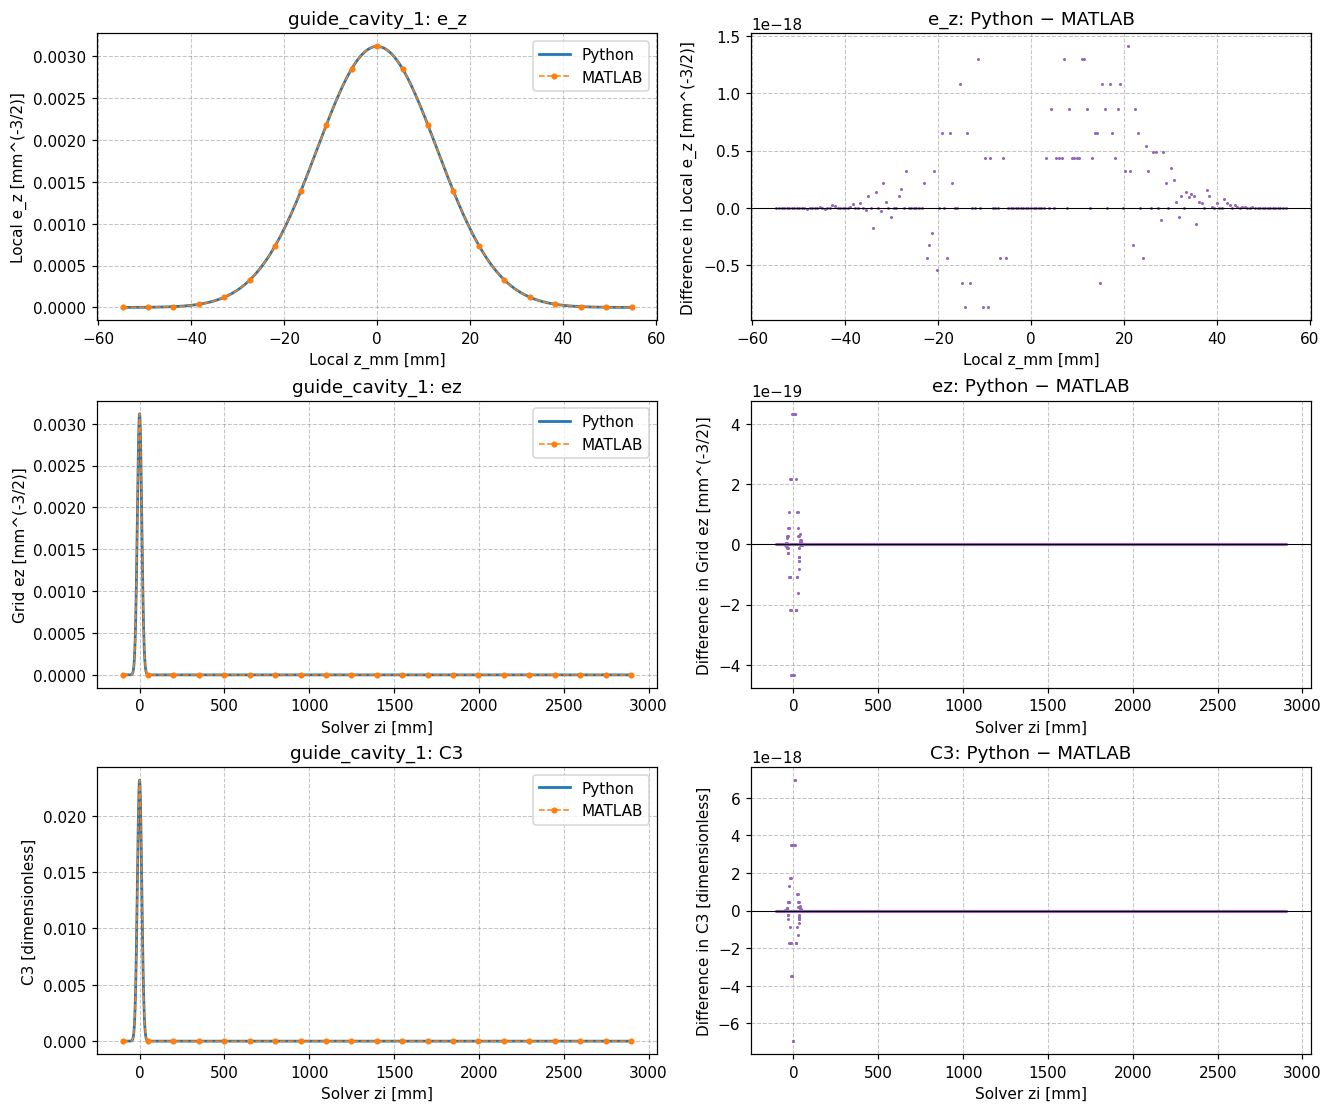

In [6]:
kk = 0  # 0 = first cavity; change this to inspect another column.

if names_match and "z_mm" in pairs and "zi" in pairs:
    assert 0 <= kk < Nc
    fig, axes = plt.subplots(3, 2, figsize=(12, 10), constrained_layout=True)
    for row, (name, label) in enumerate([
        ("e_z", "Local e_z [mm^(-3/2)]"),
        ("ez", "Grid ez [mm^(-3/2)]"),
        ("C3", "C3 [dimensionless]"),
    ]):
        if name not in pairs:
            for ax in axes[row]:
                ax.text(0.5, 0.5, f"{name}: comparison unavailable",
                        ha="center", va="center", transform=ax.transAxes)
            continue

        python_values, matlab_values = (values[:, kk] for values in pairs[name])
        if name == "e_z":
            python_z, matlab_z = (values[:, kk] for values in pairs["z_mm"])
            xlabel = "Local z_mm [mm]"
        else:
            python_z, matlab_z = pairs["zi"]
            xlabel = "Solver zi [mm]"

        ax = axes[row, 0]
        ax.plot(python_z, python_values, label="Python", linewidth=1.8)
        ax.plot(matlab_z, matlab_values, "--o", label="MATLAB", markersize=3,
                markevery=max(1, matlab_values.size // 20), linewidth=1)
        ax.set_title(f"{python_names[kk]}: {name}")
        ax.set_ylabel(label)
        ax.legend()

        ax = axes[row, 1]
        ax.plot(matlab_z, python_values - matlab_values, ".", markersize=2, color="tab:purple")
        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_title(f"{name}: Python − MATLAB")
        ax.set_ylabel(f"Difference in {label}")
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useOffset=False)

        for ax in axes[row]:
            ax.set_xlabel(xlabel)
            ax.grid(True, color="gray", linestyle="--", linewidth=0.7, alpha=0.45)
    plt.show()
else:
    print("Plots unavailable: check the cavity names and coordinate arrays in the summary.")


## 5. Per-cavity errors

The maximum absolute errors below help locate a discrepancy in an individual column. The earlier summary checks every value of every exported numerical quantity, including the local coordinates and integral diagnostics.


In [7]:
if names_match and all(name in pairs for name in ("e_z", "ez", "C3")):
    table = [
        "| Cavity | Max local e_z error [mm^(-3/2)] | Max grid ez error [mm^(-3/2)] | Max C3 error |",
        "|---|---|---|---|",
    ]
    for kk, name in enumerate(python_names):
        errors = [
            np.max(abs(pairs[key][0][:, kk] - pairs[key][1][:, kk]))
            for key in ("e_z", "ez", "C3")
        ]
        table.append(f"| {name} | " + " | ".join(f"{error:.3e}" for error in errors) + " |")
    display(Markdown("\n".join(table)))
else:
    print("Per-cavity table unavailable: inspect the numerical summary.")


| Cavity | Max local e_z error [mm^(-3/2)] | Max grid ez error [mm^(-3/2)] | Max C3 error |
|---|---|---|---|
| guide_cavity_1 | 1.409e-18 | 4.337e-19 | 6.939e-18 |
| guide_cavity_2 | 9.758e-19 | 3.469e-18 | 2.429e-17 |
| guide_cavity_3 | 6.505e-19 | 1.561e-17 | 1.128e-16 |
| guide_cavity_4 | 1.735e-18 | 9.714e-17 | 7.095e-16 |
| guide_cavity_5 | 2.168e-18 | 7.546e-17 | 5.603e-16 |

## 6. Final result

A pass establishes agreement of the saved **Gaussian maps, solver-grid fields and their normalization**, under the stated tolerances. It does not test text-field import, a cavity circuit solution, space charge or beam dynamics.

Inspect the case, variable, dimensions and calculation before changing tolerances. The final assertion makes an incomplete or failed comparison explicit when running all cells.


In [8]:
assert all_passed, "Cavity-field comparison did not pass. Review the numerical summary."
print(f"PASS: all {len(variables)} numerical quantities and the cavity-name order agree.")


PASS: all 19 numerical quantities and the cavity-name order agree.
